# Ringkasan Eksperimen Normalizer Task 1

## Setup

In [1]:
# Imports and Paths
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

repo = Path.cwd()
while not (repo / "pyproject.toml").exists():
    repo = repo.parent
sys.path.insert(0, str(repo / "src" / "task_1" / "normalizer"))

from config import DEV_SETS, EXTRA_SETS, NONINF_MARGIN, PROXIES, TEST_SETS

RES = repo / "outputs" / "task_1" / "results"
RUNS = repo / "outputs" / "task_1" / "runs"
DEV = list(DEV_SETS)
TEST = [n for n in TEST_SETS if n not in EXTRA_SETS]
pd.set_option("display.precision", 4)

In [2]:
# Plot Style
WIN, OTHER, BASE, ZERO = "#2a78d6", "#b4b2ab", "#eb6834", "#6250d6"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]    # urutan tetap, lolos uji CVD
INK, MUTED, GRID = "#0b0b0b", "#6b6a65", "#e4e3df"
DIVERGE = LinearSegmentedColormap.from_list("err", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
    "legend.frameon": False,
})

In [3]:
# Result Loaders
def read_tsv(path):
    """file tsv -> DataFrame"""
    return pd.read_csv(path, sep="\t")


def load_stage(name):
    """nama tahap -> (table, pairs, decision)"""
    folder = RES / f"stage_{name}"
    pairs = read_tsv(folder / "pairs.tsv") if (folder / "pairs.tsv").exists() else None
    return read_tsv(folder / "table.tsv"), pairs, json.loads((folder / "decision.json").read_text())


def role_color(config, winner):
    """nama config -> warna sesuai peran"""
    if config == winner:
        return WIN
    if config.startswith("base_"):
        return BASE
    if "zeroshot" in config:
        return ZERO
    return OTHER


def fmt_p(p):
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"

In [4]:
# Chart Helpers
def plot_macro(ax, table, winner, best=None, xmin=None):
    """table tahap -> bar macro-ERR dengan std antar seed"""
    configs = table["config"].tolist()
    y = np.arange(len(configs))[::-1]
    vals = table["macro_err"].to_numpy()
    shown = vals if xmin is None else np.maximum(vals, xmin)
    ax.barh(y, shown, xerr=table["macro_err_std"], height=0.62, color=[role_color(c, winner) for c in configs],
            error_kw={"ecolor": INK, "elinewidth": 0.8, "capsize": 2}, edgecolor="white", linewidth=1)
    for yi, v, s in zip(y, vals, shown):
        clipped = xmin is not None and v < xmin
        label = f"{v:.3f} (terpotong)" if clipped else f"{v:.3f}"
        ax.text(max(s, 0) + 0.01, yi, label, va="center", fontsize=8, color=INK)
    names = [c + ("  [pemenang]" if c == winner else "  [skor terbaik]" if c == best and best != winner else "")
             for c in configs]
    ax.set_yticks(y, names)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_xlabel("macro-ERR")
    ax.grid(axis="y", visible=False)
    if xmin is not None:
        ax.set_xlim(left=xmin)
    ax.set_xlim(right=max(vals.max() * 1.18, 0.1))


def plot_heat(ax, table, sets, split_after=None):
    """table tahap -> heatmap ERR per set"""
    mat = table[[f"err_{n}" for n in sets]].to_numpy(dtype=float)
    norm = TwoSlopeNorm(vcenter=0, vmin=min(np.nanmin(mat), -0.1), vmax=1)
    ax.imshow(mat, cmap=DIVERGE, norm=norm, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            dark = abs(norm(v) - 0.5) > 0.3
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8, color="white" if dark else INK)
    ax.set_xticks(range(len(sets)), sets, rotation=20, ha="right")
    ax.set_yticks(range(len(table)), table["config"])
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    if split_after is not None:
        ax.axvline(split_after - 0.5, color=INK, linewidth=1.5)


def plot_forest(ax, pairs, margin=0.0, labels=("tidak lebih buruk signifikan", "lebih buruk signifikan")):
    """pairs.tsv -> delta macro-ERR + CI 95% vs config terbaik"""
    y = np.arange(len(pairs))[::-1]
    for yi, (_, r) in zip(y, pairs.iterrows()):
        color = WIN if r["acceptable"] else OTHER
        ax.plot([r["ci_low"], r["ci_high"]], [yi, yi], color=color, linewidth=2)
        ax.plot(r["delta"], yi, "o", markersize=7, color=color, markeredgecolor="white", markeredgewidth=1.5)
        ax.text(1.02, yi, f"{r['delta']:+.4f}  {fmt_p(r['p_holm'])}", transform=ax.get_yaxis_transform(),
                va="center", fontsize=8, color=INK)
    ax.set_yticks(y, [f"{c} vs {v}" for c, v in zip(pairs["config"], pairs["vs"])])
    ax.axvline(0, color=MUTED, linewidth=0.8)
    if margin:
        ax.axvline(-margin, color=MUTED, linewidth=0.8, linestyle="--")
        ax.text(-margin, 0.02, f" margin -{margin:g}", transform=ax.get_xaxis_transform(), fontsize=8, color=MUTED)
    ax.set_ylim(-0.6, len(pairs) - 0.4)
    ax.set_xlabel("delta macro-ERR (bootstrap berpasangan, p Holm)")
    ax.grid(axis="y", visible=False)
    ax.plot([], [], "o", color=WIN, label=labels[0])
    ax.plot([], [], "o", color=OTHER, label=labels[1])
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8)


def show_stage(name, title, margin=0.0):
    """nama tahap -> tabel keputusan, bar, heatmap, forest plot"""
    table, pairs, dec = load_stage(name)
    print(f"pemenang: {dec['winner']} | skor terbaik: {dec['best_score']} | macro-ERR {dec['macro_err']:.4f}")
    h = 0.45 * len(table) + 1.2
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, h), gridspec_kw={"width_ratios": [1.3, 1]})
    plot_macro(a1, table, dec["winner"], dec["best_score"])
    a1.set_title(f"{title}: macro-ERR dev (rata-rata 3 seed, garis = std)")
    plot_heat(a2, table, DEV)
    a2.set_title("ERR per set dev")
    a2.set_yticks([])
    fig.tight_layout()
    plt.show()
    if pairs is not None:
        fig, ax = plt.subplots(figsize=(9, max(0.45 * len(pairs) + 1.4, 2.2)))
        plot_forest(ax, pairs, margin)
        ax.set_title(f"{title}: uji vs {pairs['vs'].iloc[0]}", pad=22)
        fig.tight_layout()
        plt.show()
    return table

## Alur Keputusan

In [5]:
# Decision Chain
rows = []
for s in "abcdef":
    _, _, dec = load_stage(s)
    rows.append({"tahap": s.upper(), "pemenang": dec["winner"], "skor terbaik": dec["best_score"],
                 "macro-ERR dev": dec["macro_err"], "backbone": dec["params"]["backbone"],
                 "mix": dec["params"]["mix"], "up": dec["params"]["up"], "fmt": dec["params"]["fmt"],
                 "lr": dec["params"]["lr"], "opsi": dec.get("opts", "")})
pd.DataFrame(rows)

,tahap,pemenang,skor terbaik,macro-ERR dev,backbone,mix,up,fmt,lr,opsi
0,A,byt5-small,byt5-small,0.7751,byt5-small,c,1,delim,0.001,
1,B,c1,c1,0.7066,flan-t5-small,c,1,delim,0.001,
2,C,delim,delim,0.7066,flan-t5-small,c,1,delim,0.001,
3,D,lr1e-3,lr3e-4,0.7066,flan-t5-small,c,1,delim,0.001,
4,E,target-base,target-base,0.7751,byt5-small,c,1,delim,0.001,
5,F,greedy-wl0-rp0,beam4-wl1-rp0,0.7751,byt5-small,c,1,delim,0.001,"{'beams': 1, 'whitelist': False, 'repair': False}"


## Tahap A: Backbone

pemenang: byt5-small | skor terbaik: byt5-small | macro-ERR 0.7751


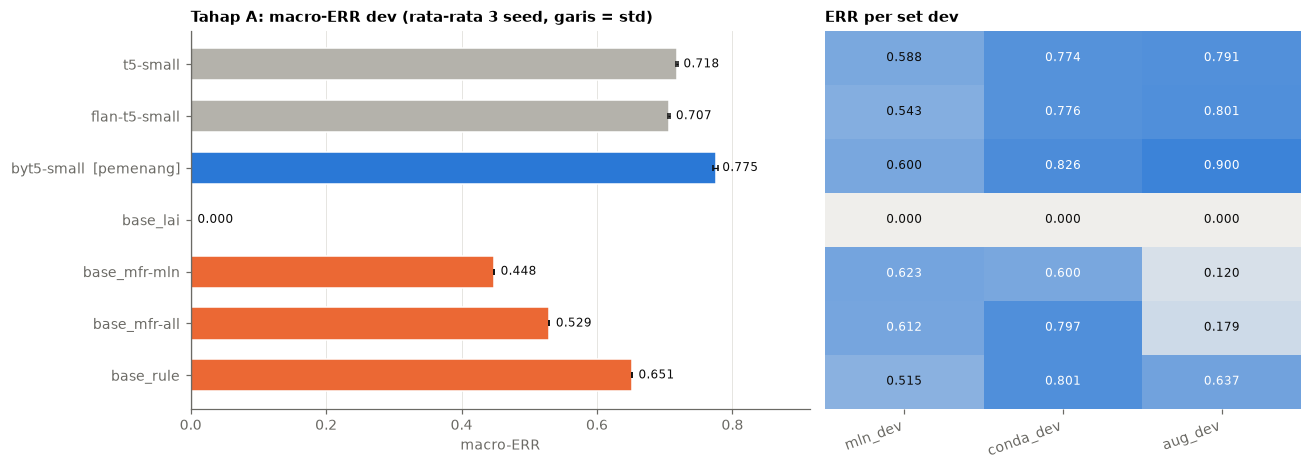

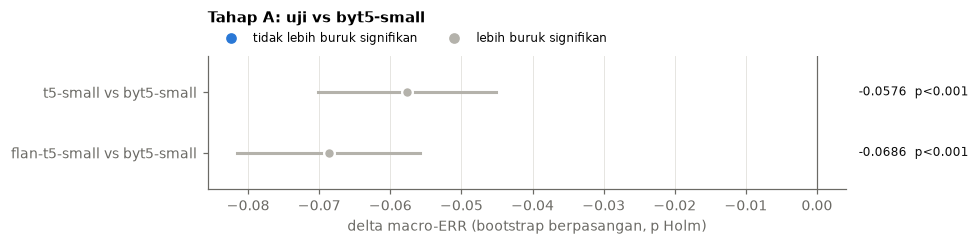

In [6]:
table_a = show_stage("a", "Tahap A")

### Kurva Training

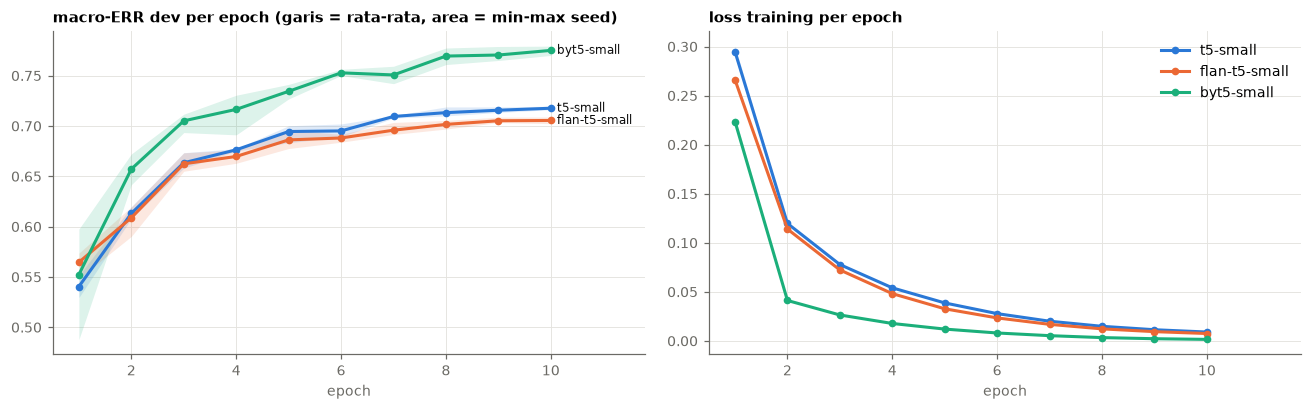

In [7]:
# Training Curves
def history(prefix):
    """prefix run -> DataFrame epoch x seed (macro-ERR dev dan loss)"""
    frames = []
    for path in sorted(RUNS.glob(f"{prefix}_s*/metrics.json")):
        hist = pd.DataFrame(json.loads(path.read_text())["history"])
        hist["seed"] = path.parent.name.rsplit("_s", 1)[1]
        frames.append(hist)
    return pd.concat(frames)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
for color, bb in zip(SERIES, ["t5-small", "flan-t5-small", "byt5-small"]):
    hist = history(f"a_{bb}")
    for key, ax in [("macro_err", a1), ("loss", a2)]:
        agg = hist.groupby("epoch")[key].agg(["mean", "min", "max"])
        ax.fill_between(agg.index + 1, agg["min"], agg["max"], color=color, alpha=0.15, linewidth=0)
        ax.plot(agg.index + 1, agg["mean"], color=color, linewidth=2, marker="o", markersize=4, label=bb)
        if key == "macro_err":
            ax.annotate(bb, (agg.index[-1] + 1, agg["mean"].iloc[-1]), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=8, color=INK)
a1.set_title("macro-ERR dev per epoch (garis = rata-rata, area = min-max seed)")
a2.set_title("loss training per epoch")
for ax in (a1, a2):
    ax.set_xlabel("epoch")
    ax.set_xlim(0.5, 11.8)
a2.legend(loc="upper right")
fig.tight_layout()
plt.show()

### Biaya Training

In [8]:
# Training Cost
cost = []
for path in sorted(RUNS.glob("*_s*/metrics.json")):
    m = json.loads(path.read_text())
    cfg = json.loads((path.parent / "config.json").read_text())
    cost.append({"run": path.parent.name.rsplit("_s", 1)[0], "seed": cfg["seed"], "lane": cfg["lane"],
                 "backbone": cfg["backbone"], "epoch": len(m["history"]), "best_epoch": m["best_epoch"] + 1,
                 "jam": m["train_hours"], "vram_gb": m["peak_vram_gb"]})
cost = pd.DataFrame(cost)
print("total jam GPU per lane:")
print(cost.groupby("lane")["jam"].agg(["count", "sum"]).round(2).to_string())
cost.pivot_table(index=["backbone", "run"], columns="seed", values=["jam", "best_epoch"]).round(2)

total jam GPU per lane:
        count    sum
lane                
colab      10  15.48
kaggle     10  20.89
local      14  27.34


best_epoch               jam            
seed                                    13    42    2026  13    42    2026
backbone      run                                                         
byt5-small    a_byt5-small              10.0  10.0  10.0  3.96  6.58  3.93
              e_byt5-small-a1            NaN   NaN   7.0   NaN   NaN  0.33
              e_byt5-small-b1            NaN   NaN  10.0   NaN   NaN  2.48
              e_byt5-small-lr3e-3        NaN   NaN  10.0   NaN   NaN  7.15
              e_byt5-small-plain         NaN   NaN  10.0   NaN   NaN  2.95
flan-t5-small a_flan-t5-small            8.0  10.0  10.0  1.78  1.75  1.49
              b_a1                       8.0   9.0  10.0  0.07  0.11  0.07
              b_b1                       8.0   8.0   8.0  1.01  1.39  1.04
              b_b4                      10.0  10.0   9.0  1.81  2.06  1.87
              b_c4                      10.0  10.0   9.0  1.77  2.53  1.78
              c_plain                   10.0  10.0   6.0  1.10  1.42  0.89
              d_lr3e-3                   9.0  10.0  10.0  1.24  1.82  1.23
              d_lr3e-4                  10.0   8.0   7.0  1.23  1.76  1.15
t5-small      a_t5-small                10.0  10.0  10.0  1.52  1.49  0.98

## Tahap B: Komposisi Data

pemenang: c1 | skor terbaik: c1 | macro-ERR 0.7066


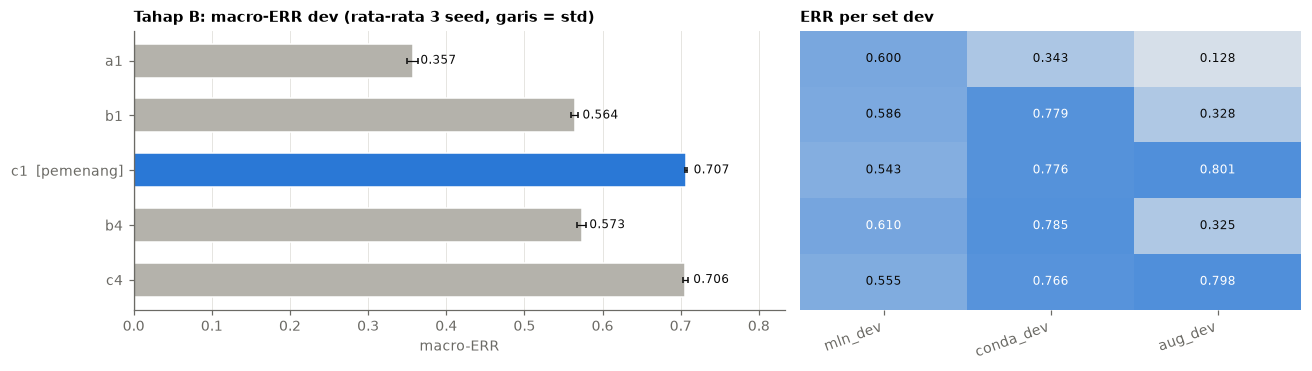

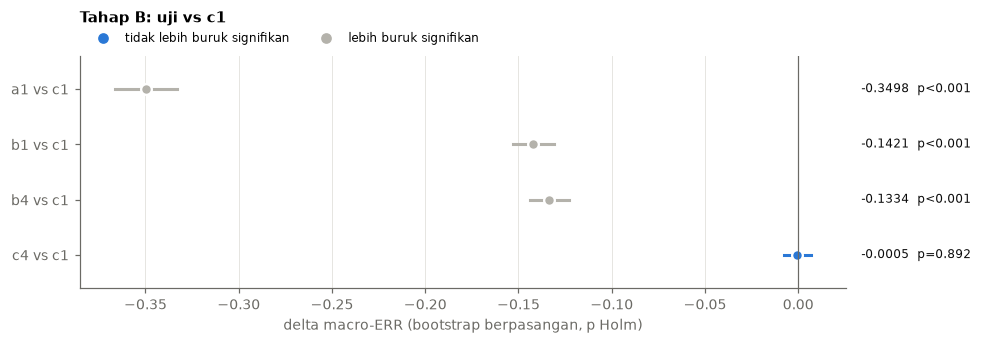

In [9]:
table_b = show_stage("b", "Tahap B")

## Tahap C: Format Output

pemenang: delim | skor terbaik: delim | macro-ERR 0.7066


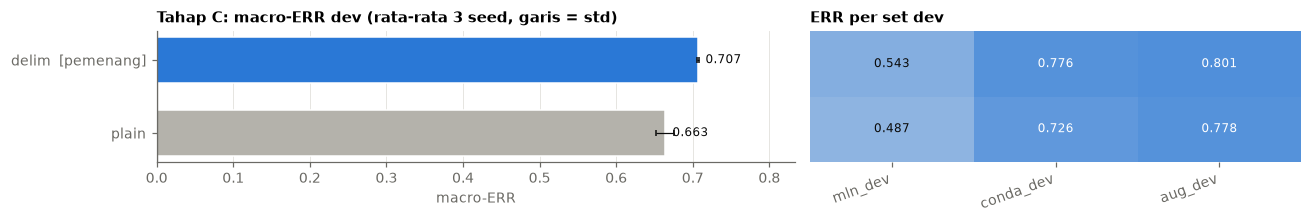

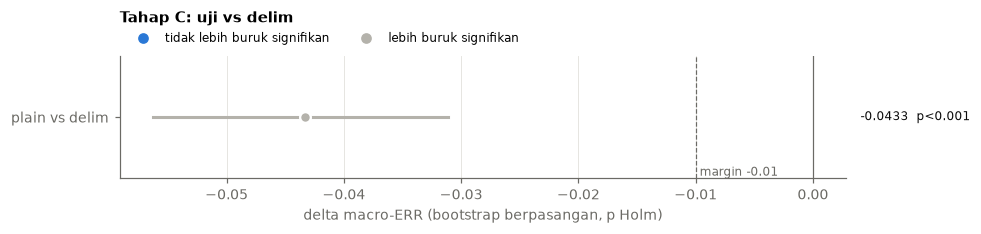

In [10]:
table_c = show_stage("c", "Tahap C", margin=NONINF_MARGIN)

## Tahap D: Learning Rate

pemenang: lr1e-3 | skor terbaik: lr3e-4 | macro-ERR 0.7066


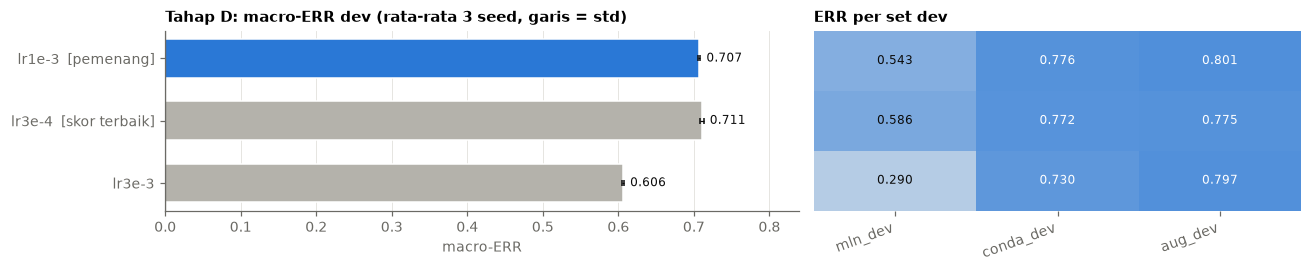

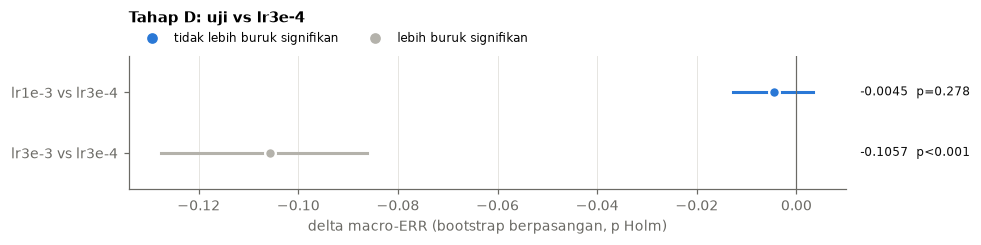

In [11]:
table_d = show_stage("d", "Tahap D")

## Tahap E: Kandidat Final

pemenang: target-base | skor terbaik: target-base | macro-ERR 0.7751


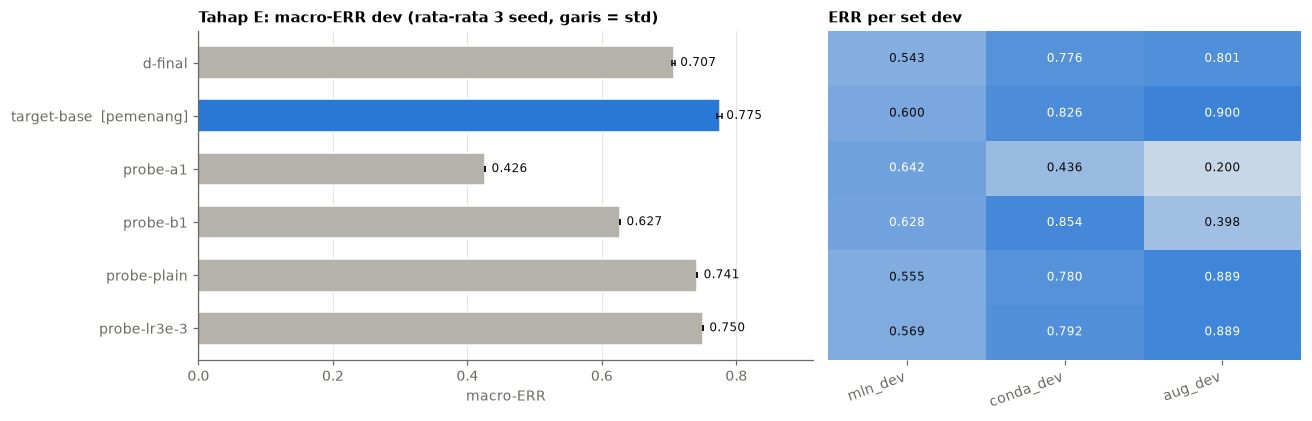

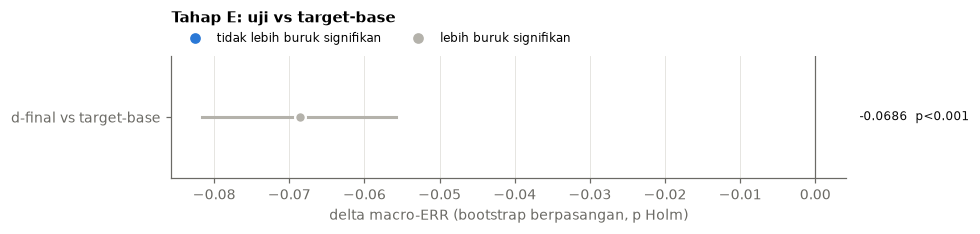

In [12]:
table_e = show_stage("e", "Tahap E")

### Transfer Proxy ke Target

In [13]:
# Transfer Points
transfer = read_tsv(RES / "stage_e" / "transfer.tsv")
summary = json.loads((RES / "stage_e" / "transfer_summary.json").read_text())
proxy, target = summary["proxy"], summary["target"]
wide = transfer[transfer["model"] != "target/proxy"].pivot_table(index=["z", "set"], columns="model",
                                                                    values="rel_pct").reset_index()
print(f"arah sama: {summary['direction_agree']} | Pearson perubahan relatif macro: {summary['pearson_rel_pct']:.3f}")
wide

arah sama: 4/4 | Pearson perubahan relatif macro: 0.972


model,z,set,byt5-small,flan-t5-small
0,a1,aug_dev,-77.8347,-84.0091
1,a1,conda_dev,-47.1491,-55.7799
2,a1,macro,-45.0565,-49.4985
3,a1,mln_dev,7.0147,10.3787
4,b1,aug_dev,-55.7502,-59.0512
5,b1,conda_dev,3.4211,0.4464
6,b1,macro,-19.1466,-20.1098
7,b1,mln_dev,4.6823,7.9380
8,lr3e-3,aug_dev,-1.2103,-0.5273
9,lr3e-3,conda_dev,-4.1405,-5.8858


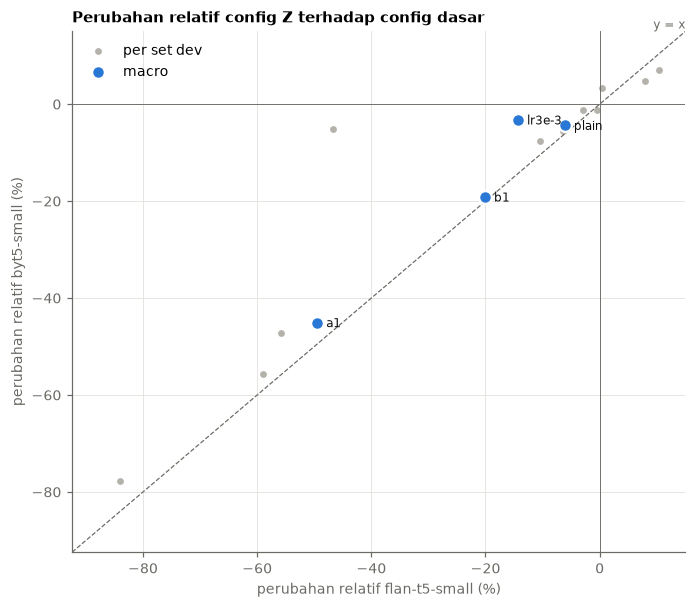

In [14]:
# Transfer Scatter
fig, ax = plt.subplots(figsize=(6.4, 5.6))
lim = [wide[[proxy, target]].min().min() * 1.1, max(wide[[proxy, target]].max().max() * 1.3, 15)]
ax.plot(lim, lim, color=MUTED, linewidth=0.8, linestyle="--")
ax.text(lim[1], lim[1], "y = x", fontsize=8, color=MUTED, ha="right", va="bottom")
ax.axhline(0, color=MUTED, linewidth=0.6)
ax.axvline(0, color=MUTED, linewidth=0.6)
per_set = wide[wide["set"] != "macro"]
ax.scatter(per_set[proxy], per_set[target], s=30, color=OTHER, edgecolor="white", label="per set dev")
macro_pts = wide[wide["set"] == "macro"]
ax.scatter(macro_pts[proxy], macro_pts[target], s=70, color=WIN, edgecolor="white", linewidth=1.5,
           label="macro", zorder=3)
for _, r in macro_pts.iterrows():
    ax.annotate(r["z"], (r[proxy], r[target]), xytext=(6, -3), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel(f"perubahan relatif {proxy} (%)")
ax.set_ylabel(f"perubahan relatif {target} (%)")
ax.set_title("Perubahan relatif config Z terhadap config dasar")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

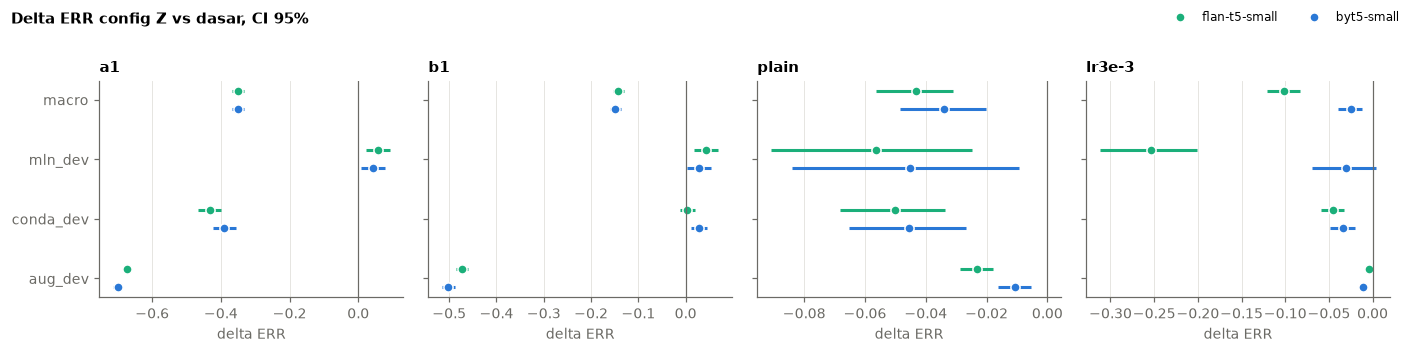

In [15]:
# Transfer Delta per Config
zs = summary["points"]
fig, axes = plt.subplots(1, len(zs), figsize=(3.2 * len(zs), 3.2), sharey=True)
sets = ["macro"] + DEV
for ax, z in zip(axes, zs):
    for k, (model, color) in enumerate([(proxy, SERIES[2]), (target, SERIES[0])]):
        part = transfer[(transfer["model"] == model) & (transfer["z"] == z)].set_index("set").loc[sets]
        y = np.arange(len(sets))[::-1] + (0.15 if k == 0 else -0.15)
        ax.hlines(y, part["ci_low"], part["ci_high"], color=color, linewidth=2)
        ax.plot(part["delta"], y, "o", color=color, markersize=6, markeredgecolor="white", label=model)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_title(z)
    ax.set_xlabel("delta ERR")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(sets))[::-1], sets)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, fontsize=8)
fig.suptitle("Delta ERR config Z vs dasar, CI 95%", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## Tahap F: Opsi Inferensi

pemenang: greedy-wl0-rp0 | skor terbaik: beam4-wl1-rp0 | macro-ERR 0.7751


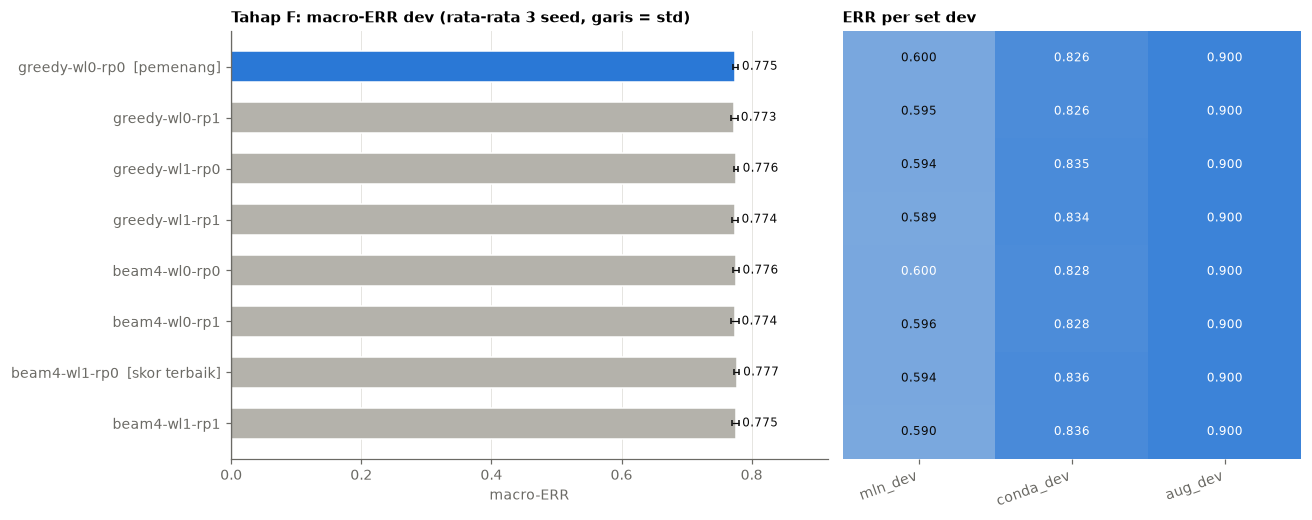

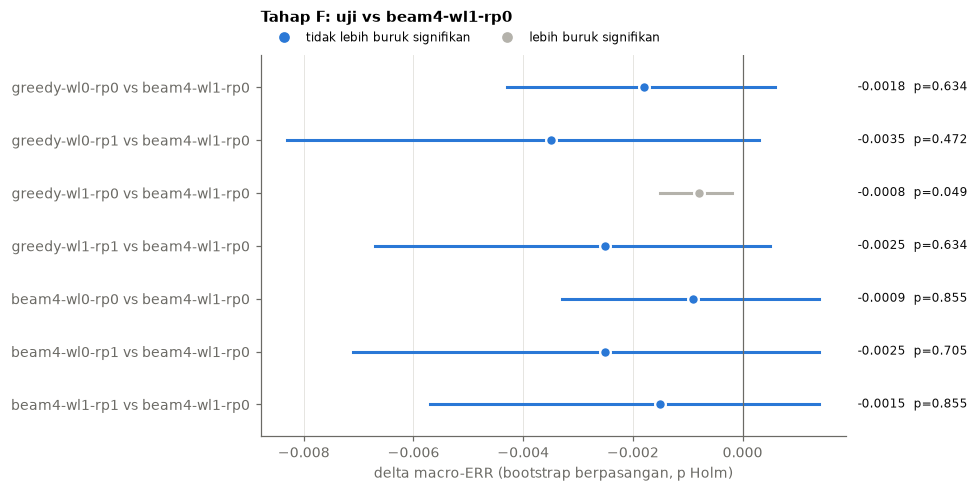

In [16]:
table_f = show_stage("f", "Tahap F")

In [17]:
# Option Effects
opts = table_f.assign(decode=table_f["config"].str.split("-").str[0],
                      whitelist=table_f["config"].str.contains("wl1"),
                      repair=table_f["config"].str.contains("rp1"))
base_f = opts.loc[opts["config"] == "greedy-wl0-rp0", "macro_err"].iloc[0]
effects = pd.DataFrame({
    "beam4": opts.groupby("decode")["macro_err"].mean().diff().iloc[-1] * -1,
    "whitelist": opts.groupby("whitelist")["macro_err"].mean().diff().iloc[-1],
    "repair": opts.groupby("repair")["macro_err"].mean().diff().iloc[-1],
}, index=["efek rata-rata macro-ERR"]).T
print(f"greedy tanpa opsi: {base_f:.4f}")
effects

greedy tanpa opsi: 0.7751


,efek rata-rata macro-ERR
beam4,0.0010
whitelist,0.0010
repair,-0.0016


## Test

### Macro-ERR Test

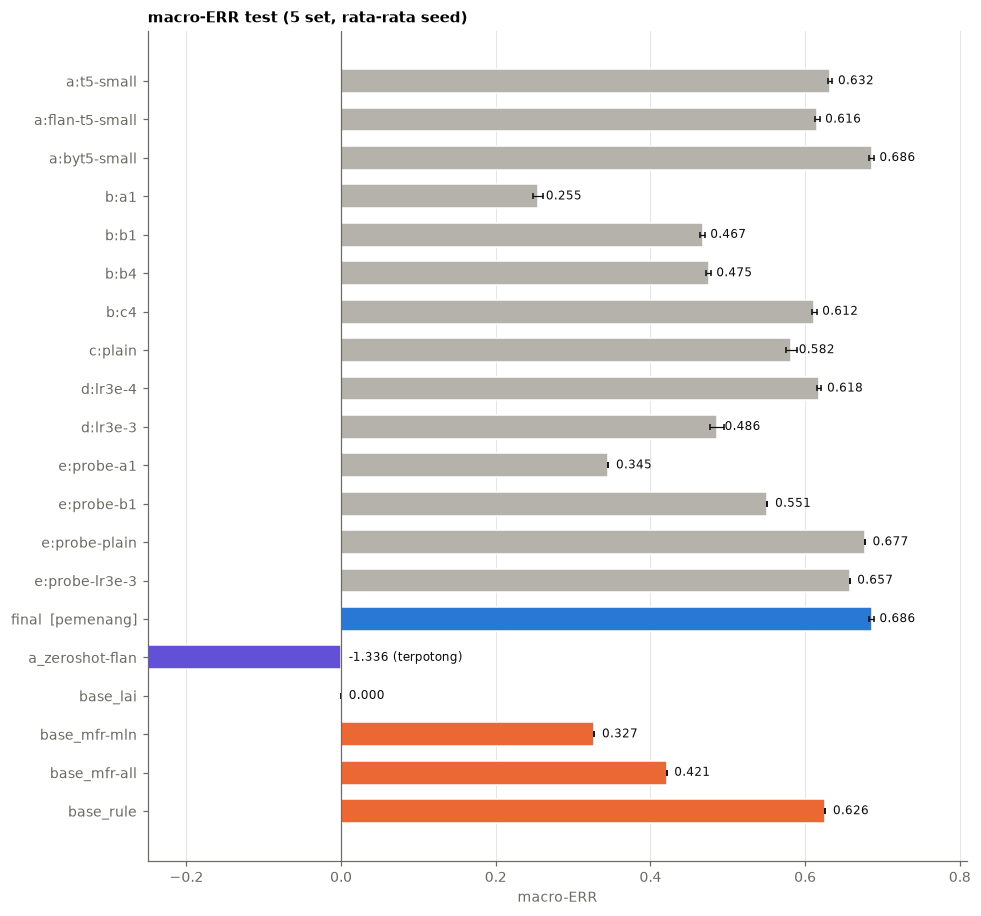

In [18]:
# Test Table
final = read_tsv(RES / "final" / "table.tsv")
fig, ax = plt.subplots(figsize=(9, 0.36 * len(final) + 1.2))
plot_macro(ax, final, "final", xmin=-0.25)
ax.set_title("macro-ERR test (5 set, rata-rata seed)")
fig.tight_layout()
plt.show()

### ERR per Set Test

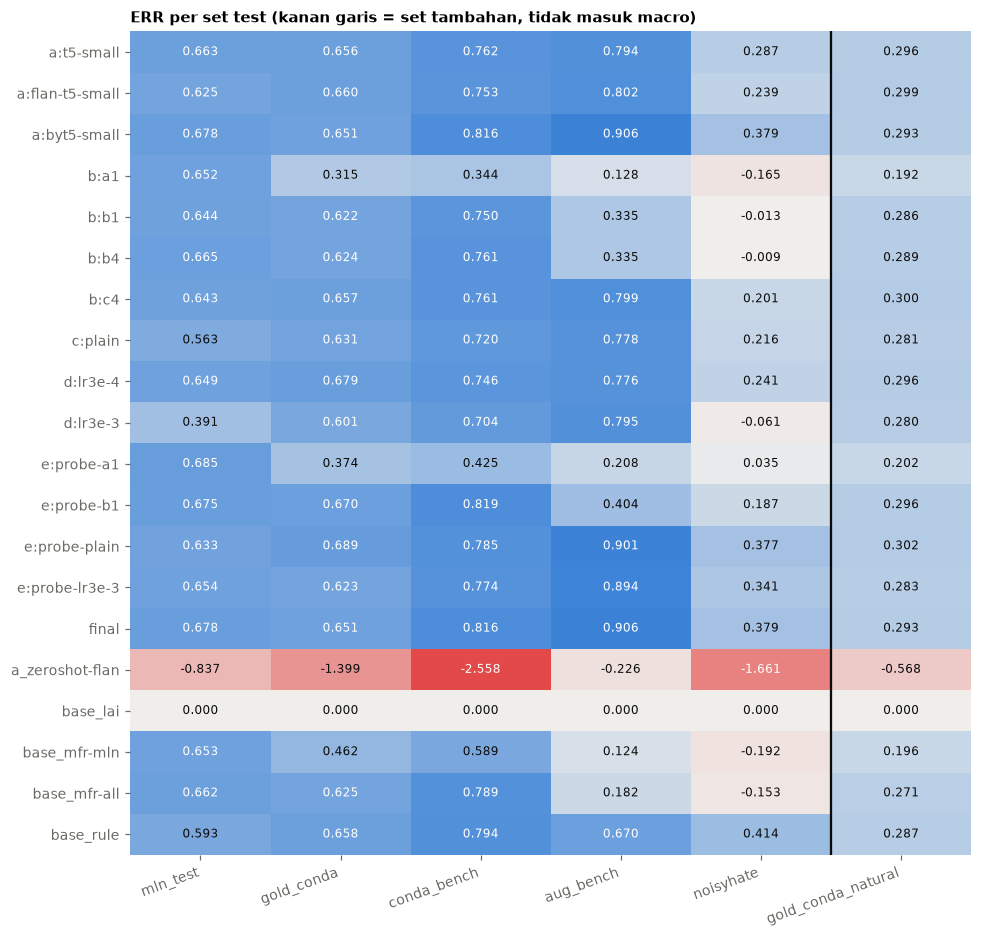

In [19]:
fig, ax = plt.subplots(figsize=(9, 0.36 * len(final) + 1.4))
plot_heat(ax, final, TEST + EXTRA_SETS, split_after=len(TEST))
ax.set_title("ERR per set test (kanan garis = set tambahan, tidak masuk macro)")
fig.tight_layout()
plt.show()

### Final vs Pembanding

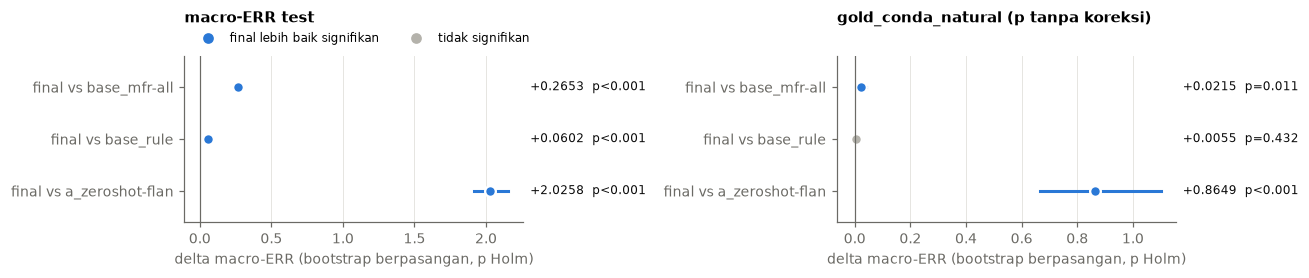

,config,vs,delta,ci_low,ci_high,p,best_better_seeds,common_seeds,acceptable,p_holm
0,final,base_mfr-all,0.2653,0.2521,0.2782,0.0,0,0,True,0.0
1,final,base_rule,0.0602,0.0478,0.0721,0.0,0,0,True,0.0
2,final,a_zeroshot-flan,2.0258,1.9137,2.1539,0.0,0,0,True,0.0


In [20]:
# Final Pairs
pairs_final = read_tsv(RES / "final" / "pairs.tsv")
natural = read_tsv(RES / "final" / "natural_pairs.tsv")
signif = ("final lebih baik signifikan", "tidak signifikan")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 2.6))
plot_forest(a1, pairs_final.assign(acceptable=pairs_final["ci_low"] > 0), labels=signif)
a1.set_title("macro-ERR test", pad=22)
natural = natural.assign(acceptable=natural["ci_low"] > 0, p_holm=natural["p"])
plot_forest(a2, natural, labels=signif)
a2.set_title("gold_conda_natural (p tanpa koreksi)", pad=22)
a2.get_legend().remove()
fig.tight_layout()
plt.show()
pairs_final

### Akurasi per Jenis Obfuskasi

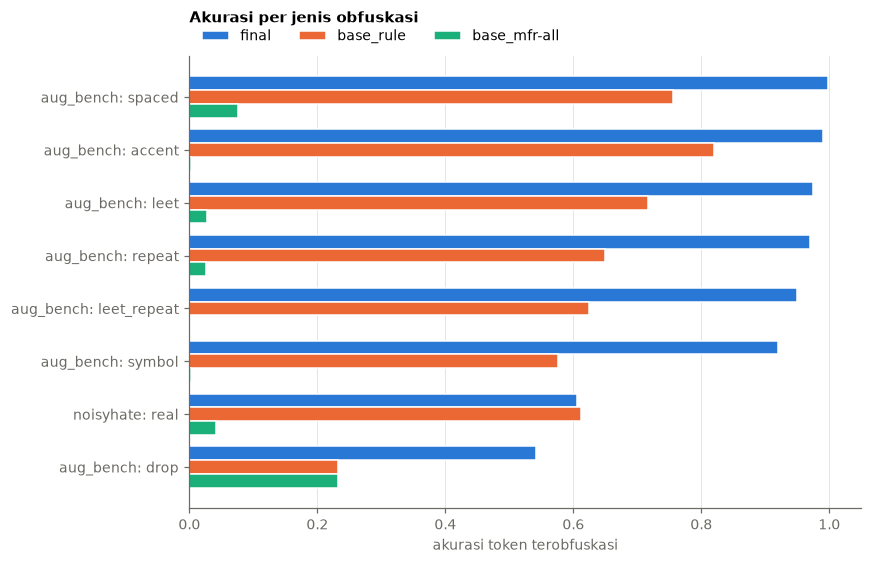

config,final,base_rule,base_mfr-all
label,,,
aug_bench: drop,0.541,0.232,0.232
noisyhate: real,0.605,0.611,0.042
aug_bench: symbol,0.920,0.577,0.002
aug_bench: leet_repeat,0.949,0.625,0.000
aug_bench: repeat,0.970,0.650,0.026
aug_bench: leet,0.974,0.717,0.027
aug_bench: accent,0.990,0.820,0.002
aug_bench: spaced,0.998,0.755,0.075


In [21]:
# Obfuscation Types
metrics = read_tsv(RES / "final" / "metrics.tsv")
compare = ["final", "base_rule", "base_mfr-all"]
obf = metrics[metrics["metric"].str.startswith("obf_acc_") & metrics["config"].isin(compare)
              & metrics["set"].isin(["aug_bench", "noisyhate"])].copy()
obf["label"] = obf["set"] + ": " + obf["metric"].str.removeprefix("obf_acc_")
wide_obf = obf.pivot_table(index="label", columns="config", values="mean")[compare]
wide_obf = wide_obf.sort_values("final")

fig, ax = plt.subplots(figsize=(8, 0.5 * len(wide_obf) + 1.2))
y = np.arange(len(wide_obf))
h = 0.26
for k, (cfg, color) in enumerate(zip(compare, SERIES)):
    ax.barh(y + (1 - k) * h, wide_obf[cfg], height=h, color=color, edgecolor="white", linewidth=1, label=cfg)
ax.set_yticks(y, wide_obf.index)
ax.set_xlim(0, 1.05)
ax.set_xlabel("akurasi token terobfuskasi")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
ax.set_title("Akurasi per jenis obfuskasi", pad=22)
fig.tight_layout()
plt.show()
wide_obf.round(3)

### Contoh Normalisasi Model Final

In [22]:
# Normalization Examples
from align import postprocess
from common import load_set, read_preds, split_slots

FINAL_RUN = "a_byt5-small_s2026"
EXAMPLE_SETS = ["gold_conda", "noisyhate", "aug_bench"]
rng = np.random.default_rng(0)


def pick(rows, n):
    """list contoh -> n contoh acak, urutan asli dipertahankan"""
    return [rows[i] for i in sorted(rng.choice(len(rows), min(n, len(rows)), replace=False))]


def examples(name, n=3):
    """nama set -> (contoh tidak diubah, contoh diubah) dari run final"""
    preds = read_preds(RUNS / FINAL_RUN / "pred" / "test_greedy" / f"{name}.tsv")
    unchanged, changed = [], []
    for r in load_set(name):
        src = split_slots(r["src"])
        # kalimat pendek supaya mudah dibaca
        if not 4 <= len(src) <= 14:
            continue
        pred, _ = postprocess(r["src"], preds[r["id"]], "delim")
        gold = split_slots(r["tgt"])
        row = {"set": name, "input": " ".join(src), "output": " ".join(pred), "gold": " ".join(gold),
               "perubahan": ", ".join(f"{s} -> {p}" for s, p in zip(src, pred) if s != p),
               "sesuai gold": pred == gold}
        (changed if row["perubahan"] else unchanged).append(row)
    return pick(unchanged, n), pick(changed, n)


same, diff = [], []
for name in EXAMPLE_SETS:
    u, c = examples(name)
    same += u
    diff += c
pd.set_option("display.max_colwidth", None)
print(f"run: {FINAL_RUN}, decode greedy tanpa whitelist dan repair")

run: a_byt5-small_s2026, decode greedy tanpa whitelist dan repair


#### Tidak Diubah

In [23]:
pd.DataFrame(same).drop(columns="perubahan")

,set,input,output,gold,sesuai gold
0,gold_conda,ez setnry by sniper,ez setnry by sniper,easy sentry by sniper,False
1,gold_conda,like buyback can possibly help :),like buyback can possibly help :),like buyback can possibly help :),True
2,gold_conda,got a few good picks on you recently,got a few good picks on you recently,got a few good picks on you recently,True
3,noisyhate,let them kill their own,let them kill their own,let them kill their own,True
4,noisyhate,cry me a river you fat f,cry me a river you fat f,cry me a river you fat f,True
5,noisyhate,mike you are definitely gay face it,mike you are definitely gay face it,mike you are definitely gay face it,True
6,aug_bench,not supid like gyro,not supid like gyro,not stupid like gyro,False
7,aug_bench,snper lost game for them,snper lost game for them,sniper lost game for them,False
8,aug_bench,don't be tose guys,don't be tose guys,don't be those guys,False


#### Diubah

In [24]:
pd.DataFrame(diff)

,set,input,output,gold,perubahan,sesuai gold
0,gold_conda,fuk u windows 10,fuck you windows 10,fuck you windows 10,"fuk -> fuck, u -> you",True
1,gold_conda,fucking hate u all,fucking hate you all,fucking hate you all,u -> you,True
2,gold_conda,bkb lasted longer anyway she dead by taht time,bkb lasted longer anyway she dead by that time,bkb lasted longer anyway she dead by that time,taht -> that,True
3,noisyhate,dammn got to revert back to cash only,damn got to revert back to cash only,damn got to revert back to cash only,dammn -> damn,True
4,noisyhate,canada is an embarassment,canada is an embarrassment,canada is an embarrassment,embarassment -> embarrassment,True
5,noisyhate,where is cheese manning when you need a tuff b¡tch,where is cheese manning when you need a tuff batch,where is cheese manning when you need a tuff bitch,b¡tch -> batch,False
6,aug_bench,who j*u*m*p high fall down,who jump high fall down,who jump high fall down,j*u*m*p -> jump,True
7,aug_bench,u guys are winn1ng,you guys are winning,you guys are winning,"u -> you, winn1ng -> winning",True
8,aug_bench,w h y u aim me,why you aim me,why you aim me,"w h y -> why, u -> you",True


### Metrik Pendukung

In [25]:
# Supporting Metrics
keep = ["precision", "recall", "f1", "overnorm", "overnorm_protected", "toxic_acc", "validity"]
support = metrics[metrics["config"].isin(compare + ["a_zeroshot-flan"]) & metrics["metric"].isin(keep)]
support.pivot_table(index=["set", "config"], columns="metric", values="mean")[keep].round(3)

metric                              precision  recall     f1  overnorm  \
set                config                                                
aug_bench          a_zeroshot-flan      0.021   0.010  0.014     0.166   
                   base_mfr-all         0.988   0.182  0.307     0.000   
                   base_rule            0.953   0.672  0.788     0.001   
                   final                0.960   0.910  0.934     0.002   
conda_bench        a_zeroshot-flan      0.015   0.044  0.023     0.248   
                   base_mfr-all         0.994   0.789  0.880     0.000   
                   base_rule            0.962   0.819  0.885     0.002   
                   final                0.909   0.873  0.891     0.005   
gold_conda         a_zeroshot-flan      0.018   0.031  0.023     0.194   
                   base_mfr-all         0.965   0.625  0.758     0.000   
                   base_rule            0.966   0.658  0.783     0.000   
                   final                0.862   0.676  0.758     0.003   
gold_conda_natural a_zeroshot-flan      0.021   0.017  0.019     0.195   
                   base_mfr-all         0.891   0.276  0.422     0.002   
                   base_rule            0.897   0.292  0.441     0.002   
                   final                0.802   0.301  0.437     0.003   
mln_test           a_zeroshot-flan      0.042   0.044  0.043     0.075   
                   base_mfr-all         0.911   0.708  0.797     0.004   
                   base_rule            0.817   0.727  0.769     0.011   
                   final                0.846   0.777  0.810     0.008   
noisyhate          a_zeroshot-flan      0.016   0.030  0.021     0.152   
                   base_mfr-all         0.175   0.042  0.067     0.018   
                   base_rule            0.715   0.611  0.659     0.018   
                   final                0.646   0.605  0.625     0.020   

metric                              overnorm_protected  toxic_acc  validity  
set                config                                                    
aug_bench          a_zeroshot-flan               0.115      0.229     1.000  
                   base_mfr-all                  0.000      0.386     1.000  
                   base_rule                     0.001      0.867     1.000  
                   final                         0.001      0.962     1.000  
conda_bench        a_zeroshot-flan               0.106      0.739     1.000  
                   base_mfr-all                  0.000      0.954     1.000  
                   base_rule                     0.003      0.960     1.000  
                   final                         0.004      0.984     1.000  
gold_conda         a_zeroshot-flan               0.074      0.658     1.000  
                   base_mfr-all                  0.000      0.930     1.000  
                   base_rule                     0.000      0.940     1.000  
                   final                         0.005      0.952     1.000  
gold_conda_natural a_zeroshot-flan               0.110      0.620     1.000  
                   base_mfr-all                  0.000      0.855     1.000  
                   base_rule                     0.000      0.864     1.000  
                   final                         0.000      0.877     1.000  
mln_test           a_zeroshot-flan               0.051      0.556     1.000  
                   base_mfr-all                  0.000      0.915     1.000  
                   base_rule                     0.000      0.919     1.000  
                   final                         0.005      0.934     0.995  
noisyhate          a_zeroshot-flan               0.085      0.417     1.000  
                   base_mfr-all                  0.000      0.478     1.000  
                   base_rule                     0.000      0.836     1.000  
                   final                         0.000      0.814     1.000

### Konsistensi Dev dan Test

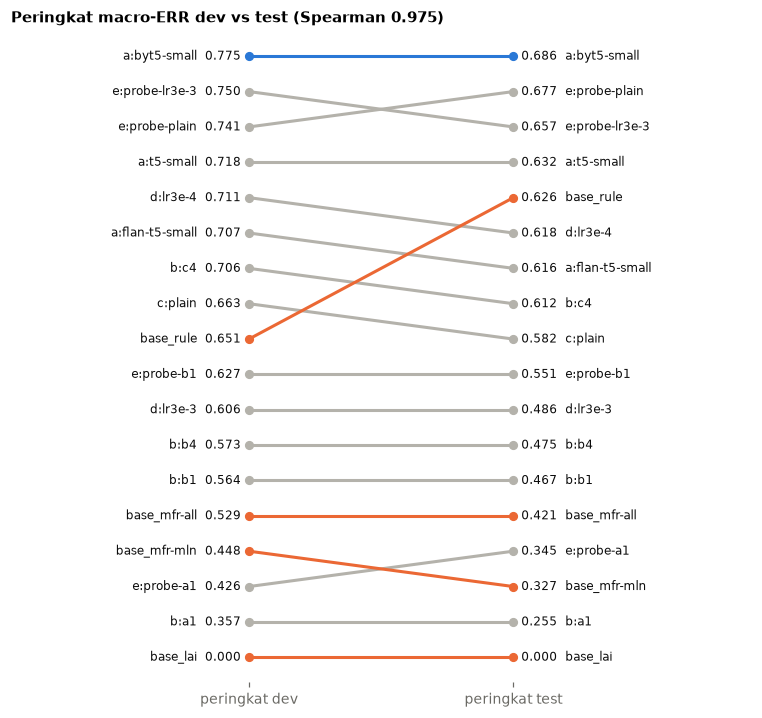

In [26]:
# Dev vs Test
dev_rows = []
for s in "abcde":
    table, _, _ = load_stage(s)
    for _, r in table.iterrows():
        name = r["config"] if r["config"].startswith("base_") else f"{s}:{r['config']}"
        dev_rows.append({"config": name, "dev": r["macro_err"]})
dev_df = pd.DataFrame(dev_rows).drop_duplicates("config")
both = dev_df.merge(final[["config", "macro_err"]].rename(columns={"macro_err": "test"}), on="config")
rho = both[["dev", "test"]].corr(method="spearman").iloc[0, 1]

both["rank_dev"] = both["dev"].rank(ascending=False, method="first")
both["rank_test"] = both["test"].rank(ascending=False, method="first")

fig, ax = plt.subplots(figsize=(7, 0.3 * len(both) + 1.2))
for _, r in both.iterrows():
    color = BASE if r["config"].startswith("base_") else WIN if r["config"] == "a:byt5-small" else OTHER
    ax.plot([0, 1], [r["rank_dev"], r["rank_test"]], color=color, linewidth=2, marker="o", markersize=5,
            zorder=3 if color != OTHER else 2)
    ax.text(-0.03, r["rank_dev"], f"{r['config']}  {r['dev']:.3f}", ha="right", va="center", fontsize=8, color=INK)
    ax.text(1.03, r["rank_test"], f"{r['test']:.3f}  {r['config']}", ha="left", va="center", fontsize=8, color=INK)
ax.set_xlim(-0.9, 1.9)
ax.set_ylim(len(both) + 0.7, 0.3)
ax.set_xticks([0, 1], ["peringkat dev", "peringkat test"])
ax.set_yticks([])
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title(f"Peringkat macro-ERR dev vs test (Spearman {rho:.3f})")
fig.tight_layout()
plt.show()